# 2 · Sector capacity from radio occupancy (Audio-DORATASK × Radio-Traffic)

Step 2 turns labelled speech segments and traffic entry times into a capacity estimate.
It runs here on a **synthetic month** of approach-sector operations whose radio service is known,
so the estimates can be checked against the truth.

| Symbol | Meaning |
|---|---|
| $D_\alpha(h) = D_{CTL}(h) + \alpha\,D_{PIL}(h)$ | hourly voice load; $\alpha$ weights pilot speech (field parameter, 0.2 and 0.7 tested) |
| $N(h)$ | TMA entries in hour $h$ |
| $d_{radio}$ | radio service per movement: estimator (mean, median, P70, P85) of $D_\alpha(h)/N(h)$ over peak hours |
| $C_{DORA}(\varphi_c) = \varphi_c \cdot 3600 / d_{radio}$ | analytical capacity, linear in the voice fraction $\varphi_c$ |
| $X$, $Y_2$ | occupancy and entry rate of a sliding window |
| $C_{emp}(X)$ | empirical saturating curve fitted on $(X, Y_2)$ |
| $\varphi_c^*, C^*$ | intersection of the two: voice fraction and capacity consistent with both |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))   # run from notebooks/ without installing
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
EST_COLORS = {"mean": "#1f77b4", "p50": "#ff7f0e", "p70": "#2ca02c", "p85": "#d62728"}

In [2]:
from atsvc import capacity, synthetic

truth = synthetic.GroundTruth()
pred, traffic = synthetic.simulate_operations(days=28, truth=truth, seed=7)
print(f"{len(traffic):,} flights, {len(pred):,} speech/noise segments over 28 days")
pred.drop(columns=["truth", "flight"]).head()   # same columns as the classifier output

5,785 flights, 72,267 speech/noise segments over 28 days


,segment_id,source_file,start_s,end_s,duration_s,prediction,confidence,t_start
0,seg000000,2024_1_31_23_30_0_ch17.wav,1675.030,1677.864,2.834,PILOT,0.747,2024-01-31 23:57:55.030072607
1,seg000001,2024_1_31_23_30_0_ch17.wav,1678.359,1681.999,3.640,CTL,0.957,2024-01-31 23:57:58.359146665
2,seg000002,2024_2_1_0_0_0_ch17.wav,213.596,216.203,2.607,PILOT,0.796,2024-02-01 00:03:33.596358705
3,seg000003,2024_2_1_0_0_0_ch17.wav,216.774,224.343,7.569,PILOT,0.545,2024-02-01 00:03:36.774227245
4,seg000004,2024_2_1_0_0_0_ch17.wav,231.923,233.814,1.891,NOISE,0.799,2024-02-01 00:03:51.922852556


## Analytical line: radio service per movement

In [3]:
res = capacity.estimate_capacity(pred, traffic["t_entry"], alphas=(0.2, 0.7), windows=(60, 90, 120, 180))
res.lines

,alpha,estimator,label,n_peak_hours,d_radio_s,slope
0,0.2,mean,Mean,188,23.710,151.837
1,0.2,p50,Median,188,23.351,154.168
2,0.2,p70,P70,188,25.496,141.197
3,0.2,p85,P85,188,28.086,128.180
4,0.7,mean,Mean,188,30.788,116.929
5,0.7,p50,Median,188,30.288,118.859
6,0.7,p70,P70,188,33.150,108.596
7,0.7,p85,P85,188,36.426,98.832


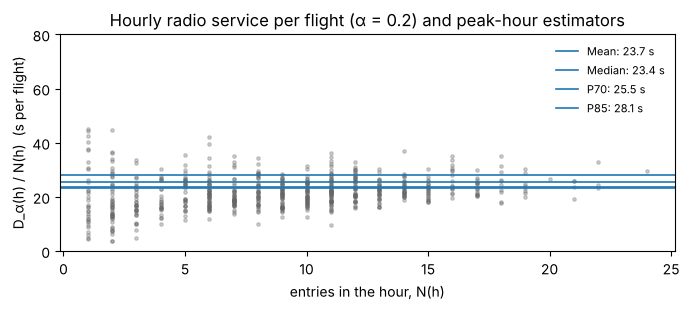

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
h = res.hourly[res.hourly["N_h"] > 0]
ax.scatter(h["N_h"], h["D_alpha_0.2"] / h["N_h"], s=6, alpha=0.3, color="0.4")
for _, r in res.lines[res.lines["alpha"] == 0.2].iterrows():
    ax.axhline(r["d_radio_s"], lw=1.2, label=f"{r['label']}: {r['d_radio_s']:.1f} s")
ax.set(xlabel="entries in the hour, N(h)", ylabel="D_α(h) / N(h)  (s per flight)",
       title="Hourly radio service per flight (α = 0.2) and peak-hour estimators", ylim=(0, 80))
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## Empirical curve: occupancy → throughput

Sliding windows give $(X, Y_2)$. Observed traffic never saturates the sector, so busy windows are
superposed (1 to 4 stacked, drawn in the top 30 % of $X$) to extend the domain. The curve is fitted
on real + superposed windows, and **scored on real windows only**. Selection per $lpha$: crosses at
least one DORATASK line, MAE < 2 flights/h, best $R^2$.

In [5]:
res.fits.drop(columns="params")

,alpha,window_min,fitted,r2_real,mae_real,n_real,n_synthetic,n_crossings,X_max_real
0,0.2,60,True,0.820,1.482,7870,32000,3,0.215
1,0.7,60,True,0.825,1.457,7870,32000,2,0.274
2,0.2,90,True,0.874,1.199,7982,32000,3,0.201
3,0.7,90,True,0.878,1.176,7982,32000,3,0.257
4,0.2,120,True,0.898,1.041,8027,32000,3,0.177
5,0.7,120,True,0.902,1.017,8027,32000,3,0.226
6,0.2,180,True,0.920,0.869,8027,32000,3,0.144
7,0.7,180,True,0.923,0.850,8027,32000,3,0.183


In [6]:
res.selected

{0.2: 180, 0.7: 180}

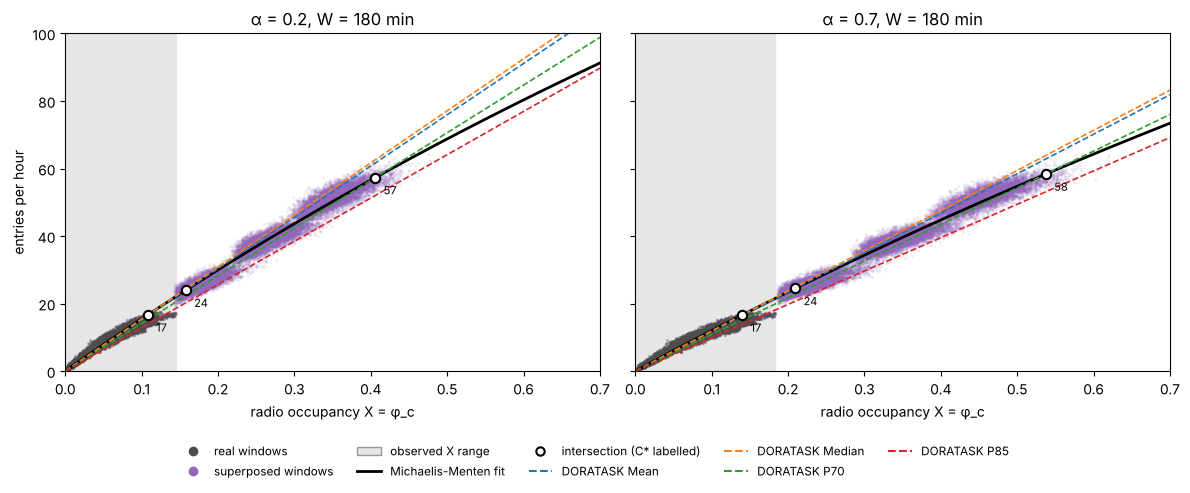

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9), sharey=True)
phi = np.linspace(0, 0.7, 200)
for ax, a in zip(axes, (0.2, 0.7)):
    w = res.selected[a]
    real, synth, curve = res.real[(a, w)], res.synthetic[(a, w)], res.curves[(a, w)]
    ax.scatter(synth["X"], synth["Y2"], s=2, alpha=0.08, color="#9467bd", label="superposed windows")
    ax.scatter(real["X"], real["Y2"], s=2, alpha=0.25, color="0.3", label="real windows")
    ax.plot(phi, curve(phi), color="k", lw=2, label="Michaelis-Menten fit")
    ax.axvspan(0, real["X"].max(), color="0.9", zorder=-1, label="observed X range")
    for _, ln in res.lines[res.lines["alpha"] == a].iterrows():
        ax.plot(phi, ln["slope"] * phi, lw=1.2, ls="--", color=EST_COLORS[ln["estimator"]],
                label=f"DORATASK {ln['label']} ({ln['d_radio_s']:.1f} s)")
    pts = res.intersections.query("alpha == @a and window_min == @w").dropna(subset=["phi_c_star"])
    ax.scatter(pts["phi_c_star"], pts["C_star"], color="k", zorder=5, s=45, marker="o",
               facecolor="white", linewidth=1.5, label="intersections")
    for _, p in pts.iterrows():
        ax.annotate(f"{p['C_star']:.0f}", (p["phi_c_star"], p["C_star"]), textcoords="offset points",
                    xytext=(6, -12), fontsize=8)
    ax.set(xlim=(0, 0.7), ylim=(0, 100), xlabel="radio occupancy X = φ_c", title=f"α = {a}, W = {w} min")
axes[0].set_ylabel("entries per hour")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
handles = [Line2D([], [], ls="", marker="o", color="0.3", label="real windows"),
           Line2D([], [], ls="", marker="o", color="#9467bd", label="superposed windows"),
           Patch(facecolor="0.9", edgecolor="0.6", label="observed X range"),
           Line2D([], [], color="k", lw=2, label="Michaelis-Menten fit"),
           Line2D([], [], ls="", marker="o", mfc="white", mec="k", mew=1.5, label="intersection (C* labelled)")]
handles += [Line2D([], [], ls="--", color=c, label=f"DORATASK {n}") for n, c in
            zip(["Mean", "Median", "P70", "P85"], EST_COLORS.values())]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig("../figures/capacity_intersections.png", dpi=150, bbox_inches="tight")

In [8]:
res.summary()

,alpha,window_min,estimator,d_radio_s,phi_c_star,C_star,extrapolated
0,0.2,180,Mean,23.710,0.158,23.959,True
1,0.2,180,Median,23.351,0.108,16.653,False
2,0.2,180,P70,25.496,0.406,57.318,True
3,0.2,180,P85,28.086,NaN,NaN,False
4,0.7,180,Mean,30.788,0.209,24.479,True
5,0.7,180,Median,30.288,0.140,16.629,False
6,0.7,180,P70,33.150,0.537,58.365,True
7,0.7,180,P85,36.426,NaN,NaN,False


## Identification diagnostic

At an intersection, $\varphi^* \cdot 3600 / d_{radio} = C_{emp}(\varphi^*)$, which rearranges to

$$s(\varphi^*) = d_{radio}, \qquad s(X) = \frac{3600\,X}{C_{emp}(X)}$$

where $s(X)$ is the radio service per flight implied by the empirical curve. So $C^*$ is the
throughput at which the fitted service per flight reaches the chosen estimator. How strongly
$C^*$ depends on that choice is set by the slope of $s(X)$: when $s$ is nearly flat, small changes in
$d_{radio}$ move $C^*$ a long way, often beyond the observed range of $X$, where the curve is an
extrapolation driven by the superposed windows. This plot should accompany any $C^*$ reported.

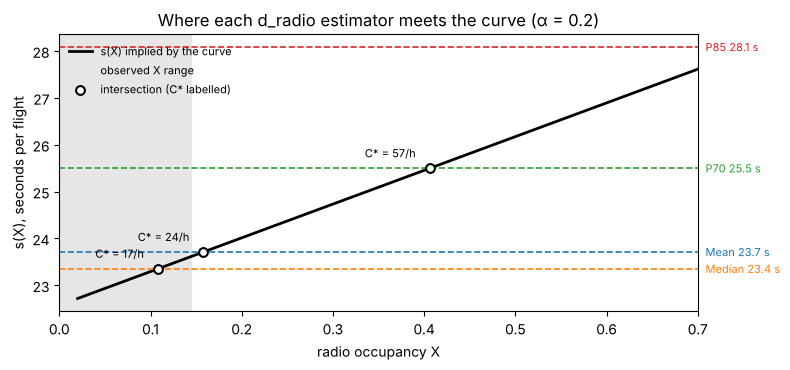

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
a, w = 0.2, res.selected[0.2]
x = np.linspace(0.02, 0.7, 300)
ax.plot(x, capacity.implied_service(res.curves[(a, w)], x), color="k", lw=2, label="s(X) implied by the curve")
ax.axvspan(0, res.real[(a, w)]["X"].max(), color="0.9", zorder=-1, label="observed X range")
for _, ln in res.lines[res.lines["alpha"] == a].iterrows():
    ax.axhline(ln["d_radio_s"], ls="--", lw=1.2, color=EST_COLORS[ln["estimator"]])
    ax.text(0.705, ln["d_radio_s"], f" {ln['label']} {ln['d_radio_s']:.1f} s", va="center", fontsize=8,
            color=EST_COLORS[ln["estimator"]])
pts = res.intersections.query("alpha == @a and window_min == @w").dropna(subset=["phi_c_star"])
ax.scatter(pts["phi_c_star"], pts["d_radio_s"], color="k", facecolor="white", zorder=5, s=40, linewidth=1.5,
           label="intersection (C* labelled)")
for _, p in pts.iterrows():
    ax.annotate(f"C* = {p['C_star']:.0f}/h", (p["phi_c_star"], p["d_radio_s"]), textcoords="offset points",
                xytext=(-10, 8), fontsize=8, ha="right")
ax.set(xlim=(0, 0.7), xlabel="radio occupancy X", ylabel="s(X), seconds per flight",
       title=f"Where each d_radio estimator meets the curve (α = {a})")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
fig.savefig("../figures/identification_diagnostic.png", dpi=150)

## Check against the ground truth

The synthetic month lets us compare the estimated radio service with the speech actually generated
for the flights entering during peak hours.

In [10]:
rows = []
for a in (0.2, 0.7):
    hours = set(capacity.peak_hours(res.hourly, a)["hour"])
    ids = set(np.flatnonzero(traffic["t_entry"].dt.floor("h").isin(hours)))
    per_flight = (pred[pred["flight"].isin(ids)]
                  .pivot_table(index="flight", columns="truth", values="duration_s", aggfunc="sum")
                  .reindex(columns=["CTL", "PILOT"]).fillna(0))
    true_d = (per_flight["CTL"] + a * per_flight["PILOT"]).mean()
    est = res.lines.query("alpha == @a and estimator == 'mean'")["d_radio_s"].item()
    rows.append({"alpha": a, "true service (s/flight)": true_d, "estimated, mean (s/flight)": est,
                 "relative error": (est - true_d) / true_d})
pd.DataFrame(rows)

,alpha,true service (s/flight),"estimated, mean (s/flight)",relative error
0,0.2,25.956,23.710,-0.087
1,0.7,33.640,30.788,-0.085


The mean estimator recovers the service with a bias of about −9 % on this month. The bias has
identifiable sources: segments dropped by the 0.70 confidence filter, CTL/PILOT label swaps (5 %
here), and exchanges that fall in a different hour from the flight's entry (first calls are made
before entry). On real data, the confidence threshold and the classifier's confusion rates bound
this error and should be reported with d_radio. The capacity itself has no ground truth here: the simulated sector has no workload
limit, which is precisely why the diagnostic above matters.

## Running on real data

```python
from atsvc.io import add_absolute_times, load_traffic
pred = add_absolute_times(pd.read_csv("predictions.csv"))       # output of notebook 1 / `atsvc predict`
traffic = load_traffic("traffic.xlsx", start="2024-02-01", end="2024-02-28")
res = capacity.estimate_capacity(pred, traffic["t_entry"])
```